In [3]:
import zipfile, os, glob
#1 unzipping the mian ibd zip folder

os.makedirs("ibd_data/raw", exist_ok=True)
with zipfile.ZipFile("IBD_small.zip", 'r') as z:
  z.extractall("ibd_data")

#2 unzipping wach individual sample into the/raw
sample_zips = glob.glob("ibd_data/**/*.zip", recursive = True)
for sz in sample_zips:
  with zipfile.ZipFile(sz, 'r') as z:
    z.extractall("ibd_data/raw")

#3listing extracted raw specrtal files and inscoecting the raw data
raw_files = sorted(os.listdir("ibd_data/raw"))
print(f"extracted {len(raw_files)} raw spectral files:")
for f in raw_files:
  print("-", f)

meta_files = glob.glob("ibd_data/**/trimmed_metadata.txt", recursive = True)
if meta_files:
  print("\n----metadata preview---")
  with open(meta_files[0]) as mf:
    print(mf.read())


extracted 10 raw spectral files:
- CD-6KUCT.mzML
- CD-77FXR.mzML
- CD-9OS5Y.mzML
- CD-9WOBP.mzML
- HC-9SNJ4.mzML
- HC-9X47O.mzML
- HC-AMR37.mzML
- HC-AUP8B.mzML
- QC_PREFA02.mzML
- QC_PREFB02.mzML

----metadata preview---
Sample	Disease
CD-6KUCT.zip	Control
CD-9OS5Y.zip	Control
CD-9WOBP.zip	Control
CD-77FXR.zip	Control
HC-9SNJ4.zip	Disease
HC-9X47O.zip	Disease
HC-AMR37.zip	Disease
HC-AUP8B.zip	Disease
QC_PREFA02.zip	QC
QC_PREFB02.zip	QC



In [4]:
!pip install -q pyopenms
import pyopenms as oms

#inspecting one raw .mzml file to check ms levels ms1 ms2 and scan couts
exp = oms.MSExperiment()
oms.MzMLFile().load("ibd_data/raw/CD-6KUCT.mzML", exp)

ms1_count = sum(1 for spec in exp if spec.getMSLevel() == 1)
ms2_count = sum(1 for spec in exp if spec.getMSLevel() == 2)

print(f"total spectra : {exp.size()}")
print(f"ms1 scans for quantification : {ms1_count}")
print(f"ms2 scans for fragmentation: {ms2_count}")

total spectra : 446
ms1 scans for quantification : 446
ms2 scans for fragmentation: 0


In [13]:
!pip install -q asari-metabolomics
!asari --help



~~~~~~~ Hello from Asari (2.0.0) ~~~~~~~~~

usage: asari [-h] [-v] [-m MODE] [--ppm PPM] [-i INPUT] [-o OUTPUT]
             [-j PROJECT] [-p PARAMETERS] [-c MULTICORES]
             [--search_algorithm {reverse,forward,mz,rtmz,csm}]
             [--preannotation PREANNOTATION]
             [--score_cutoff_cosine SCORE_CUTOFF_COSINE]
             [--lc_rt_tolerance LC_RT_TOLERANCE]
             [--score_algorithm {cosine,entropy}]
             [--deconvolution_algorithm {hcl,adap,nmf}] [--files FILES]
             [--reference REFERENCE] [--database_mode DATABASE_MODE]
             [--wlen WLEN] [--max_retention_shift MAX_RETENTION_SHIFT]
             [--num_lowess_iterations NUM_LOWESS_ITERATIONS]
             [--autoheight AUTOHEIGHT] [--min_peak_height MIN_PEAK_HEIGHT]
             [--min_prominence_threshold MIN_PROMINENCE_THRESHOLD]
             [--cal_min_peak_height CAL_MIN_PEAK_HEIGHT]
             [--min_intensity_threshold MIN_INTENSITY_THRESHOLD]
             [--peak_area 

In [14]:
#chceking the instryment settings:
!asari peek -i ibd_data/raw/CD-6KUCT.mzML



~~~~~~~ Hello from Asari (2.0.0) ~~~~~~~~~

Peek into ibd_data/raw/CD-6KUCT.mzML

term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
Total number of MS1 spectra: 446
of which 0 is positive ionization mode.
Assuming ionization mode is neg.

Total number of MS2 spectra: 0
Maximum retention time (sec): 599.808000
m/z range: (min 251.128677, median 470.230164, max 600.346313)

Found 1023 mass tracks.
Found 257 12C/13C isotopic pairs as landmarks.
Max intensity in any landmark track:  366,804,896
Minimal height of landmark tracks:  49,299 

Mass accuracy was estimated on 54 matched values as 0.3 ppm.
  Mass accuracy is estimated as 0.3 ppm.


Scan plot was written to /content/asari_project_peek_1119152254/CD-6KUCT_peek.pdf



In [15]:
#to turn the raw squiggles into a feature table-- peak picking, rt align, feature grouping.
!asari process -m neg -i ibd_data/raw -o ibd_asari_out -j ibd_project



~~~~~~~ Hello from Asari (2.0.0) ~~~~~~~~~

Working on ~~ ibd_data/raw ~~ 


term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
Extracted HC-9X47O.mzML to 492 mass tracks (0 MS2 spectra).
term not found (MS:1000031)
term not found (MS:1000031)
Extracted CD-6KUCT.mzML to 1023 mass tracks (0 MS2 spectra).
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
term not found (MS:1000031)
Extracted HC-AMR37.mzML to 1462 mass tracks (0 MS2 spectra).
term not found (MS:1000031)
term not found (MS:1000031)
Extracted QC_PREFB02.mzML to 1572 mass tracks (0 MS2 spectra).
term

In [16]:
#throwing out the garbage using the pooled qcs by pandas filtering
import glob, os
import pandas as pd

out_files = sorted(glob.glob("ibd_asari_out/**/*", recursive=True))
for f in out_files:
    print(f)

ft_path = glob.glob("ibd_asari_out/**/Feature_table.tsv", recursive=True)[0]
df_raw = pd.read_csv(ft_path, sep="\t")
print("\nShape:", df_raw.shape)
display(df_raw.head())

ibd_asari_out/ibd_project_1119152617
ibd_asari_out/ibd_project_1119152617/Feature_table.tsv
ibd_asari_out/ibd_project_1119152617/README.txt
ibd_asari_out/ibd_project_1119152617/project.json

Shape: (6832, 21)


,id_number,mz,rtime,rtime_left_base,rtime_right_base,parent_masstrack_id,peak_area,cSelectivity,goodness_fitting,snr,...,QC_PREFA02,CD-6KUCT,HC-AMR37,QC_PREFB02,HC-9X47O,HC-9SNJ4,CD-9WOBP,CD-9OS5Y,HC-AUP8B,CD-77FXR
0,F0,250.1527,593.85,590.91,597.06,0,23687796,1.00,0.95,1915,...,3331009,0,0,3282656,0,12684438,0,0,0,4413694
1,F1,253.0505,501.62,499.21,504.88,1,5409464,1.00,0.94,426,...,1640174,0,0,1857734,0,0,0,1944313,0,0
2,F2,253.1445,497.34,494.13,500.55,2,361032608,1.00,0.96,106,...,37211868,43505264,14059118,36788772,28880658,36378780,43682732,44387640,35013636,43958472
3,F3,254.1478,483.55,481.95,486.26,3,1677486,0.68,0.58,54,...,0,24396,156688,0,41138,130542,0,980981,236613,113046
4,F4,254.1478,490.06,487.33,492.46,3,1871357,0.68,0.77,47,...,0,16410,64126,19091,10991,93834,0,1432476,143028,111401


In [18]:
import numpy as np

# 1. Identify our sample columns by group
qc_cols = ["QC_PREFA02", "QC_PREFB02"]
bio_cols =  ["CD-6KUCT", "CD-9OS5Y", "CD-9WOBP", "CD-77FXR",
            "HC-9SNJ4", "HC-9X47O", "HC-AMR37", "HC-AUP8B"]

# 2. Keep features detected in at least 50% of biological samples (4 out of 8)
present_count = (df_raw[bio_cols] > 0).sum(axis=1)
df_filt = df_raw[present_count >= 4].copy()

# 3. Calculate QC RSD (%) and keep stable features (RSD < 30%)
qc_mean = df_filt[qc_cols].mean(axis=1)
qc_std = df_filt[qc_cols].std(axis=1)
df_filt["QC_RSD"] = (qc_std / qc_mean) * 100

df_clean = df_filt[(qc_mean > 0) & (df_filt["QC_RSD"] < 30)].copy()
print(f"Starting features: {len(df_raw)} -> After presence & QC RSD < 30% filter: {len(df_clean)}")

Starting features: 6832 -> After presence & QC RSD < 30% filter: 2263


In [19]:
#comparing fare-- imputationa and normlais adn log2
all_samples = qc_cols + bio_cols
mat = df_clean[all_samples].copy().astype(float)

# 1. Impute zeros with half-minimum positive intensity per feature (row)--sometimes very low mwta will be read as 0 . log20 crash -- replace with half of the lowest detected vslie of that particular metabolite.
row_min = mat.replace(0, np.nan).min(axis=1)
mat = mat.apply(lambda col: col.where(col > 0, row_min / 2.0), axis=0)

# 2. Sample-wise median normalization-- pulling all the samples to the exact baseline scale.
sample_medians = mat.median(axis=0)
mat_norm = mat.div(sample_medians, axis=1) * sample_medians.median()

# 3. Log2 transformation
mat_log2 = np.log2(mat_norm)
print("Normalized log2 matrix shape:", mat_log2.shape)
display(mat_log2.head(3))

Normalized log2 matrix shape: (2263, 10)


,QC_PREFA02,QC_PREFB02,CD-6KUCT,CD-9OS5Y,CD-9WOBP,CD-77FXR,HC-9SNJ4,HC-9X47O,HC-AMR37,HC-AUP8B
2,24.080412,24.054527,26.180064,25.073723,27.330435,25.374599,25.177935,26.770290,22.979453,25.076611
5,21.279966,21.298557,23.324450,22.266777,24.546283,22.560364,22.396862,23.891366,19.989886,22.259032
6,23.122038,23.133036,22.715369,21.461639,20.986695,20.021781,20.420974,23.163816,18.271270,21.054763


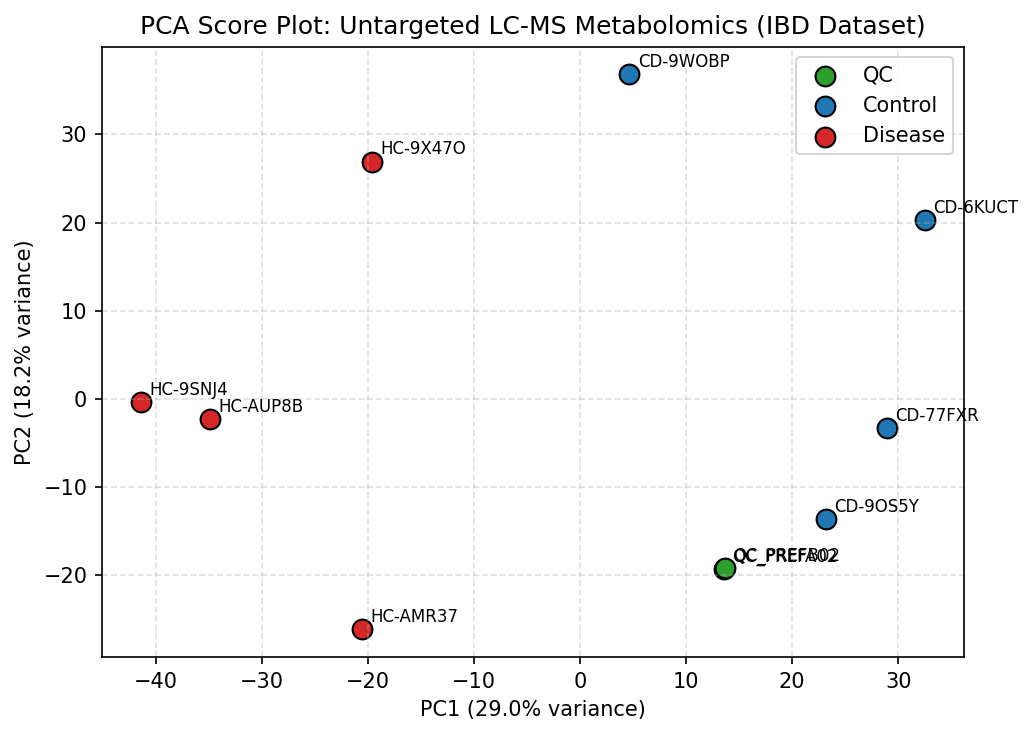

In [20]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Auto-scale features (mean=0, std=1) across samples (transpose so rows = samples)
X_scaled = StandardScaler().fit_transform(mat_log2.T)

# 2. Fit 2-component PCA
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

# 3. Assign biological groups from metadata
groups = ["QC", "QC", "Control", "Control", "Control", "Control",
          "Disease", "Disease", "Disease", "Disease"]
colors = {"QC": "#2ca02c", "Control": "#1f77b4", "Disease": "#d62728"}

# 4. Plot PCA scatter with sample labels
plt.figure(figsize=(7, 5), dpi=150)
for grp in ["QC", "Control", "Disease"]:
    idx = [i for i, g in enumerate(groups) if g == grp]
    plt.scatter(coords[idx, 0], coords[idx, 1], label=grp, color=colors[grp], s=90, edgecolors="k")

for i, sample in enumerate(all_samples):
    plt.annotate(sample, (coords[i, 0] + 0.8, coords[i, 1] + 0.8), fontsize=8)

plt.xlabel(f"PC1 ({var_exp[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({var_exp[1]:.1f}% variance)")
plt.title("PCA Score Plot: Untargeted LC-MS Metabolomics (IBD Dataset)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("ibd_pca_plot.png", dpi=300)
plt.show()

Regulation
Not Significant    1877
Up in Disease       197
Down in Disease     189
Name: count, dtype: int64


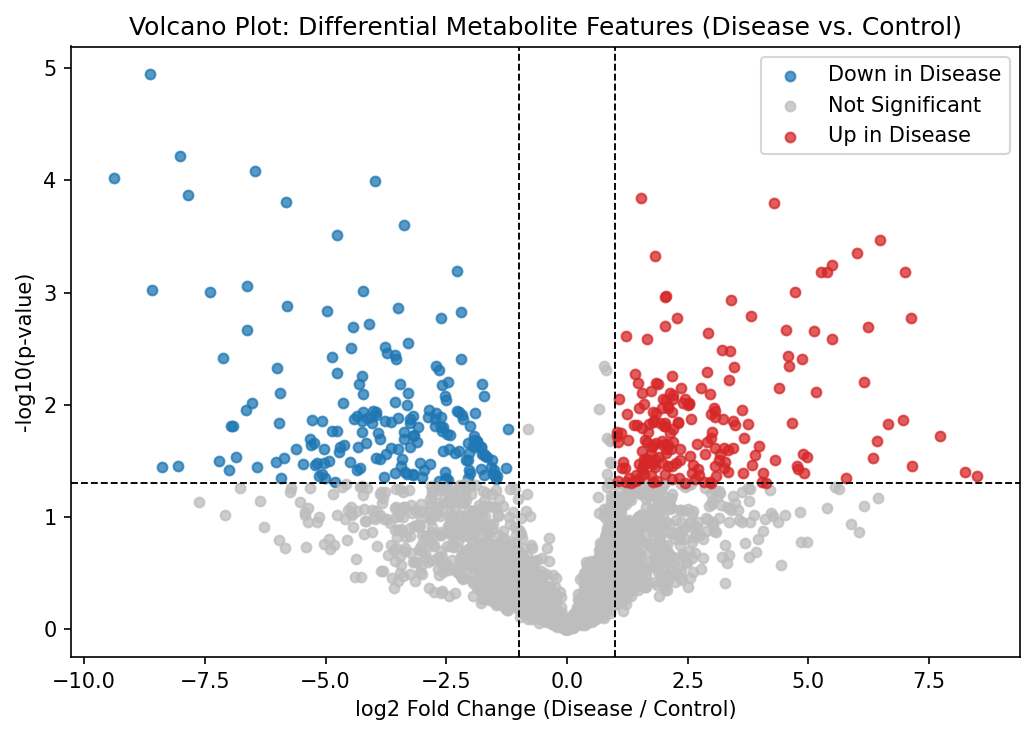

In [21]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

ctrl_cols = ["CD-6KUCT", "CD-9OS5Y", "CD-9WOBP", "CD-77FXR"]
dis_cols  = ["HC-9SNJ4", "HC-9X47O", "HC-AMR37", "HC-AUP8B"]

# 1. Compute log2FC and Welch's t-test p-values across all 2,263 features
stats_df = df_clean[["id_number", "mz", "rtime", "QC_RSD"]].copy()
stats_df["log2FC"] = mat_log2[dis_cols].mean(axis=1) - mat_log2[ctrl_cols].mean(axis=1)
_, pvals = ttest_ind(mat_log2[dis_cols], mat_log2[ctrl_cols], axis=1, equal_var=False)
stats_df["pvalue"] = pvals
stats_df["FDR"] = multipletests(stats_df["pvalue"], method="fdr_bh")[1]
stats_df["neg_log10_p"] = -np.log10(stats_df["pvalue"])

# 2. Classify Up-regulated, Down-regulated, and Non-significant features (|log2FC| >= 1, p < 0.05)
conds = [
    (stats_df["log2FC"] >= 1.0) & (stats_df["pvalue"] < 0.05),
    (stats_df["log2FC"] <= -1.0) & (stats_df["pvalue"] < 0.05)
]
stats_df["Regulation"] = np.select(conds, ["Up in Disease", "Down in Disease"], default="Not Significant")
print(stats_df["Regulation"].value_counts())

# 3. Plot Volcano Plot
plt.figure(figsize=(7, 5), dpi=150)
palette = {"Up in Disease": "#d62728", "Down in Disease": "#1f77b4", "Not Significant": "#bdbdbd"}
for reg, grp_df in stats_df.groupby("Regulation"):
    plt.scatter(grp_df["log2FC"], grp_df["neg_log10_p"], c=palette[reg], label=reg, alpha=0.75, s=22)

plt.axvline(1.0, color="k", linestyle="--", linewidth=0.9)
plt.axvline(-1.0, color="k", linestyle="--", linewidth=0.9)
plt.axhline(-np.log10(0.05), color="k", linestyle="--", linewidth=0.9)
plt.xlabel("log2 Fold Change (Disease / Control)")
plt.ylabel("-log10(p-value)")
plt.title("Volcano Plot: Differential Metabolite Features (Disease vs. Control)")
plt.legend()
plt.tight_layout()
plt.savefig("ibd_volcano_plot.png", dpi=300)
plt.show()

In [22]:
# 1. Calculate putative neutral mass for [M-H]- negative mode ions (proton mass = 1.007276 Da)
PROTON_MASS = 1.007276
stats_df["neutral_mass_Da"] = (stats_df["mz"] + PROTON_MASS).round(5)

# 2. Filter significant hits (|log2FC| >= 1.0 & p < 0.05) and sort by lowest p-value
sig_hits = stats_df[stats_df["Regulation"] != "Not Significant"].sort_values("pvalue").copy()
print(f"Total significant differential features: {len(sig_hits)}")
print(sig_hits["Regulation"].value_counts())

# 3. Export full differential results and display Top 15 hits
sig_hits.to_csv("ibd_differential_metabolites.csv", index=False)
display(sig_hits[["id_number", "mz", "neutral_mass_Da", "rtime", "QC_RSD", "log2FC", "pvalue", "FDR", "Regulation"]].head(15))

Total significant differential features: 386
Regulation
Up in Disease      197
Down in Disease    189
Name: count, dtype: int64


,id_number,mz,neutral_mass_Da,rtime,QC_RSD,log2FC,pvalue,FDR,Regulation
1301,F1301,399.1482,400.15548,506.49,2.393433,-8.630606,0.000011,0.025659,Down in Disease
1443,F1443,411.1481,412.15538,504.08,3.200806,-8.020584,0.000060,0.039712,Down in Disease
1471,F1471,413.1636,414.17088,523.93,3.937268,-6.467565,0.000083,0.039712,Down in Disease
103,F103,269.1308,270.13808,507.02,0.086448,-9.377042,0.000095,0.039712,Down in Disease
4807,F4807,559.3290,560.33628,518.26,3.938737,-3.974714,0.000101,0.039712,Down in Disease
1442,F1442,411.1481,412.15538,493.53,3.107338,-7.855262,0.000136,0.039712,Down in Disease
809,F809,351.2176,352.22488,516.65,9.597380,1.527993,0.000142,0.039712,Up in Disease
3646,F3646,528.2636,529.27088,512.11,15.053200,-5.828368,0.000154,0.039712,Down in Disease
1113,F1113,385.2056,386.21288,565.38,2.985651,4.289128,0.000158,0.039712,Up in Disease
3498,F3498,523.2728,524.28008,555.48,22.596097,-3.374132,0.000248,0.056212,Down in Disease


In [ ]:
#asari deconvolute / khipu--in ms,one single metabolite can crete upto 4 5 seprtate rows -the main, m-h- peak , heacu c13 iso peak, sodium , formate abbduct-- grouping 4212 features into 1442 emp compnds.

In [25]:
!asari deconvolute -m neg -i {ft_path} -o ibd_deconv_out

emp_path = glob.glob("ibd_deconv_out/**/Annotated_*Compounds.tsv", recursive=True)[0]
df_emp = pd.read_csv(emp_path, sep="\t")
display(df_emp.head(5))



~~~~~~~ Hello from Asari (2.0.0) ~~~~~~~~~

Result directory: /content/ibd_deconv_out/asari_project_deconvolution_1119153629.


table header looks like: 
   ['id_number', 'mz', 'rtime', 'rtime_left_base', 'rtime_right_base', 'parent_masstrack_id', 'peak_area', 'cSelectivity', 'goodness_fitting', 'snr', 'detection_counts', 'QC_PREFA02', 'CD-6KUCT', 'HC-AMR37', 'QC_PREFB02', 'HC-9X47O', 'HC-9SNJ4', 'CD-9WOBP', 'CD-9OS5Y', 'HC-AUP8B']
Read 6832 feature lines


Multiple charges considered: [1, 2, 3]


Khipu search grid: 
               M-H-       Na/H      M+Cl-  ...        ACN    M+HCOO-     NaCOOH
M0        -1.007276  20.974664  34.969402  ...  40.019273  44.998203  66.980148
13C/12C   -0.003921  21.978019  35.972757  ...  41.022628  46.001558  67.983503
37Cl/35Cl  0.989724  22.971664  36.966402  ...  42.016273  46.995203  68.977148
13C/12C*2  0.999434  22.981374  36.976112  ...  42.025983  47.004913  68.986858
13C/12C*3  2.002789  23.984729  37.979467  ...  43.029338  48.008268  69.99

IndexError: list index out of range

In [26]:
khipu_path = glob.glob("ibd_deconv_out/**/*list_khipus.tsv", recursive=True)[0]
df_emp = pd.read_csv(khipu_path, sep="\t")
display(df_emp.head(10))

,id,mz,rtime,empCpd,neutral_formula_mass,isotope,modification,ion_relation
0,F523,322.1355,497.34,kp1_254.152,254.152005,13C/12C,NaCOOH,"13C/12C,NaCOOH"
1,F6225,255.1423,496.00,kp1_254.152,254.152005,37Cl/35Cl,M-H-,"37Cl/35Cl,M-H-"
2,F2,253.1445,497.34,kp1_254.152,254.152005,M0,M-H-,"M0,M-H-"
3,F5,254.1478,497.34,kp1_254.152,254.152005,13C/12C,M-H-,"13C/12C,M-H-"
4,F514,321.1321,497.07,kp1_254.152,254.152005,M0,NaCOOH,"M0,NaCOOH"
5,F6,255.0662,510.50,kp2_256.0734,256.073399,M0,M-H-,"M0,M-H-"
6,F14,256.0694,510.77,kp2_256.0734,256.073399,13C/12C,M-H-,"13C/12C,M-H-"
7,F12,255.1601,494.93,kp3_256.1673,256.167349,M0,M-H-,"M0,M-H-"
8,F19,256.1634,496.00,kp3_256.1673,256.167349,13C/12C,M-H-,"13C/12C,M-H-"
9,F118,277.1423,501.35,kp4_256.1674,256.167445,M0,Na/H,"M0,Na/H"


In [27]:
# Merge khipu empirical compound & adduct annotations onto significant differential hits
final_metab = sig_hits.merge(
    df_emp[["id", "empCpd", "neutral_formula_mass", "ion_relation"]],
    left_on="id_number", right_on="id", how="left"
).drop(columns=["id"])

final_metab.to_csv("ibd_annotated_metabolites.csv", index=False)
display(final_metab[["id_number", "empCpd", "mz", "neutral_formula_mass", "ion_relation", "log2FC", "FDR", "Regulation"]].head(10))

,id_number,empCpd,mz,neutral_formula_mass,ion_relation,log2FC,FDR,Regulation
0,F1301,kp281_400.1555,399.1482,400.155549,"M0,M-H-",-8.630606,0.025659,Down in Disease
1,F1443,kp324_412.1556,411.1481,412.155611,"M0,M-H-",-8.020584,0.039712,Down in Disease
2,F1471,kp329_414.1709,413.1636,414.170945,"M0,M-H-",-6.467565,0.039712,Down in Disease
3,F103,kp14_270.1382,269.1308,270.138199,"M0,M-H-",-9.377042,0.039712,Down in Disease
4,F4807,kp925_560.3364,559.3290,560.336399,"M0,M-H-",-3.974714,0.039712,Down in Disease
5,F1442,kp323_412.1555,411.1481,412.155549,"M0,M-H-",-7.855262,0.039712,Down in Disease
6,F809,kp162_352.2244,351.2176,352.224449,"M0,M-H-",1.527993,0.039712,Up in Disease
7,F3646,kp416_458.2731,528.2636,458.273148,"13C/12C*3,NaCOOH",-5.828368,0.039712,Down in Disease
8,F1113,singleton,385.2056,386.212900,NaN,4.289128,0.039712,Up in Disease
9,F3498,kp1191_463.6193,523.2728,463.619337,"M0,M+HCOO-",-3.374132,0.056212,Down in Disease


In [28]:
import os, shutil
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Create a clean, GitHub-ready project folder structure
proj_folder = "LCMS_Untargeted_Metabolomics_IBD"
os.makedirs(f"{proj_folder}/results/figures", exist_ok=True)
os.makedirs(f"{proj_folder}/results/tables", exist_ok=True)

# 3. Save our normalized intensity matrix & copy all generated outputs
mat_log2.to_csv(f"{proj_folder}/results/tables/normalized_log2_feature_matrix.csv")
shutil.copy("ibd_annotated_metabolites.csv", f"{proj_folder}/results/tables/ibd_annotated_metabolites.csv")
shutil.copy(ft_path, f"{proj_folder}/results/tables/asari_raw_feature_table.tsv")
shutil.copy(khipu_path, f"{proj_folder}/results/tables/asari_khipu_empirical_compounds.tsv")

shutil.copy("ibd_pca_plot.png", f"{proj_folder}/results/figures/ibd_pca_plot.png")
shutil.copy("ibd_volcano_plot.png", f"{proj_folder}/results/figures/ibd_volcano_plot.png")

# 4. Copy the entire folder to Google Drive & create a local ZIP backup
drive_dest = f"/content/drive/MyDrive/{proj_folder}"
shutil.copytree(proj_folder, drive_dest, dirs_exist_ok=True)
shutil.make_archive(proj_folder, 'zip', proj_folder)

print("Saved successfully to Google Drive:", drive_dest)

Mounted at /content/drive
Saved successfully to Google Drive: /content/drive/MyDrive/LCMS_Untargeted_Metabolomics_IBD


In [1]:
import requests, time
import pandas as pd

# 1. Load your saved annotated table (if starting a fresh Colab session, mount Drive first)
df_top = pd.read_csv("/content/drive/MyDrive/LCMS_Untargeted_Metabolomics_IBD/results/tables/ibd_annotated_metabolites.csv").head(10)

def lookup_pubchem_mass(mass, ppm=5):
    tol = mass * (ppm / 1e6)
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/monoisotopic_mass/range/{mass - tol:.5f}/{mass + tol:.5f}/property/Title,MolecularFormula/JSON"
    r = requests.get(url, timeout=10)
    if r.status_code == 200:
        props = r.json()["PropertyTable"]["Properties"][:3]
        return "; ".join([f"{p.get('Title', 'Unknown')} ({p.get('MolecularFormula', '')})" for p in props])
    return "No exact match within 5 ppm"

# 2. Query top 10 hits
df_top["Putative_Candidates_5ppm"] = [lookup_pubchem_mass(m) for m in df_top["neutral_formula_mass"]]
display(df_top[["id_number", "neutral_formula_mass", "ion_relation", "log2FC", "FDR", "Putative_Candidates_5ppm"]])

,id_number,neutral_formula_mass,ion_relation,log2FC,FDR,Putative_Candidates_5ppm
0,F1301,400.155549,"M0,M-H-",-8.630606,0.025659,N-(trans-4-(2-Methoxyethoxy)cyclohexyl)-6-(thi...
1,F1443,412.155611,"M0,M-H-",-8.020584,0.039712,(3R)-4-(2-(1H-indol-4-yl)-6-(1-methylsulfonylc...
2,F1471,414.170945,"M0,M-H-",-6.467565,0.039712,N-6022 (C24H22N4O3); N-[7-(4-{[(3-methylphenyl...
3,F103,270.138199,"M0,M-H-",-9.377042,0.039712,Dibutyl phenylphosphonate (C14H23O3P); (2Z)-2-...
4,F4807,560.336399,"M0,M-H-",-3.974714,0.039712,Cucurbitacin C (C32H48O8); Dihydrocucurbitacin...
5,F1442,412.155549,"M0,M-H-",-7.855262,0.039712,(3R)-4-(2-(1H-indol-4-yl)-6-(1-methylsulfonylc...
6,F809,352.224449,"M0,M-H-",1.527993,0.039712,Prostaglandin E2 (C20H32O5); Prostacyclin (C20...
7,F3646,458.273148,"13C/12C*3,NaCOOH",-5.828368,0.039712,"Decaethylene glycol (C20H42O11); (1S)-1-[(4aR,..."
8,F1113,386.212900,NaN,4.289128,0.039712,"3-Methylfentanyl hydrochloride, cis- (C23H31Cl..."
9,F3498,463.619337,"M0,M+HCOO-",-3.374132,0.056212,Silver iodoarsenate (Ag2AsIO3); Tris(iron(2+))...


In [2]:
df_top.to_csv("/content/drive/MyDrive/LCMS_Untargeted_Metabolomics_IBD/results/tables/top10_pubchem_annotated.csv", index= False)